In [1]:
import pandas as pd
import os
%pip install xlrd
import matplotlib.pyplot as plt


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
sales_report = pd.read_excel("sample_-_superstore.xls")
sales_report

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2026-143259,2026-12-30,2027-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910
10190,10191,US-2026-115427,2026-12-30,2027-01-03,Standard Class,EB-13975,Erica Bern,Corporate,United States,Fairfield,...,94533,West,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750
10191,10192,US-2026-156720,2026-12-30,2027-01-03,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,...,80538,West,OFF-FA-10003472,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048
10192,10193,US-2026-143259,2026-12-30,2027-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279


In [3]:
sales_report.shape

(10194, 21)

In [4]:
sales_report.isna().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [5]:
sales_report.dtypes

Row ID                     int64
Order ID                  object
Order Date        datetime64[ns]
Ship Date         datetime64[ns]
Ship Mode                 object
Customer ID               object
Customer Name             object
Segment                   object
Country/Region            object
City                      object
State/Province            object
Postal Code               object
Region                    object
Product ID                object
Category                  object
Sub-Category              object
Product Name              object
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object

In [6]:
sales_report.duplicated().sum()

np.int64(0)

In [7]:
sales_report.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194 non-null  object        
 15  Su

In [8]:
print("Country/Region")
print(sales_report["Country/Region"].unique())
print("\nCategory")
print(sales_report["Category"].unique())
print("\nSub-Category")
print(sales_report["Sub-Category"].unique())
print("\nShip Mode")
print(sales_report["Ship Mode"].unique())


Country/Region
['United States' 'Canada']

Category
['Office Supplies' 'Furniture' 'Technology']

Sub-Category
['Paper' 'Binders' 'Labels' 'Storage' 'Art' 'Chairs' 'Fasteners' 'Phones'
 'Furnishings' 'Accessories' 'Bookcases' 'Envelopes' 'Appliances' 'Tables'
 'Supplies' 'Machines' 'Copiers']

Ship Mode
['Standard Class' 'First Class' 'Second Class' 'Same Day']


In [9]:
sales_report[["Sales","Quantity","Discount","Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417
std,619.906839,2.228317,0.206249,232.465115
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.220000,2.000000,0.000000,1.760800
50%,53.910000,3.000000,0.200000,8.690000
75%,209.500000,5.000000,0.200000,29.297925
max,22638.480000,14.000000,0.800000,8399.976000


In [11]:
discount_analysis = (
    sales_report.groupby("Discount")["Profit"]
    .agg(["count","mean","sum"])
    .round(2)
)
discount_analysis

,count,mean,sum
Discount,,,
0.00,4925,66.34,326718.59
0.10,96,94.79,9099.97
0.15,52,27.29,1418.99
0.20,3706,24.58,91079.95
0.30,230,-45.71,-10513.45
0.32,27,-88.56,-2391.14
0.40,207,-111.53,-23086.37
0.45,11,-226.65,-2493.11
0.50,66,-310.70,-20506.43


In [12]:
region_analysis = (
    sales_report.groupby("Region")["Profit"]
    .agg(["count","mean","sum"])
    .round(2)
    .sort_values("sum", ascending=False)
)
region_analysis

,count,mean,sum
Region,,,
West,3253,34.06,110798.82
East,2986,31.78,94883.26
South,1620,28.86,46749.43
Central,2335,17.07,39865.31


In [13]:
category_analysis = (
    sales_report.groupby("Category")["Profit"]
    .agg(["count","mean","sum"])
    .round(2)
    .sort_values("sum", ascending=False)
)
category_analysis

,count,mean,sum
Category,,,
Technology,1865,78.58,146543.38
Office Supplies,6128,20.57,126023.44
Furniture,2201,8.96,19730.00


In [14]:
sub_category_analysis = (
    sales_report.groupby("Sub-Category")["Profit"]
    .agg(["count","mean","sum"])
    .round(2)
    .sort_values("sum", ascending=False)
)
sub_category_analysis

,count,mean,sum
Sub-Category,,,
Copiers,70,801.34,56093.94
Phones,903,49.89,45050.83
Accessories,775,54.11,41936.64
Paper,1384,24.94,34511.51
Binders,1548,20.30,31426.10
Chairs,634,42.94,27223.53
Storage,856,24.87,21285.11
Appliances,474,38.67,18329.48
Furnishings,1009,13.77,13891.74


In [15]:
region_category_analysis = (
    sales_report.groupby(["Region","Category"])["Profit"]
    .sum()
    .unstack()
    .round(2)
)
region_category_analysis

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2802.21,8970.08,33697.43
East,3444.74,42996.74,48441.78
South,6771.21,19986.39,19991.83
West,12316.25,54070.23,44412.34


In [16]:
sales_report.nlargest(10,"Profit")[["Order ID","Product Name","Sales","Quantity","Discount","Profit"]]

,Order ID,Product Name,Sales,Quantity,Discount,Profit
5894,US-2025-118689,Canon imageCLASS 2200 Advanced Copier,17499.950,5,0.0,8399.9760
7255,US-2026-140151,Canon imageCLASS 2200 Advanced Copier,13999.960,4,0.0,6719.9808
9517,US-2026-166709,Canon imageCLASS 2200 Advanced Copier,10499.970,3,0.0,5039.9856
6674,US-2025-117121,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,13,0.0,4946.3700
1203,US-2023-116904,Ibico EPK-21 Electric Binding System,9449.950,5,0.0,4630.4755
9171,US-2026-127180,Canon imageCLASS 2200 Advanced Copier,11199.968,4,0.2,3919.9888
2242,US-2024-145352,Fellowes PB500 Electric Punch Plastic Comb Bin...,6354.950,5,0.0,3177.4750
4282,US-2025-158841,HP Designjet T520 Inkjet Large Format Printer ...,8749.950,5,0.0,2799.9840
5907,US-2025-140158,Hewlett Packard LaserJet 3310 Copier,5399.910,9,0.0,2591.9568
6882,US-2026-138289,GBC DocuBind P400 Electric Binding System,5443.960,4,0.0,2504.2216


In [17]:
product_profit = (
    sales_report.groupby("Product Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
product_profit

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64

In [18]:
total_sales = sales_report["Sales"].sum()
total_profit = sales_report["Profit"].sum()

profit_margin = (total_profit / total_sales)*100

print("Total Sales :", round(total_sales,2))
print("Total Profit :", round(total_profit,2))
print("Total Profit Margin :", round(profit_margin,2),"%")
 

Total Sales : 2326534.35
Total Profit : 292296.81
Total Profit Margin : 12.56 %


In [19]:
print("Total Sales Records:", len(sales_report))
print("Total Sales Amount:", round(sales_report["Sales"].sum(), 2))

Total Sales Records: 10194
Total Sales Amount: 2326534.35


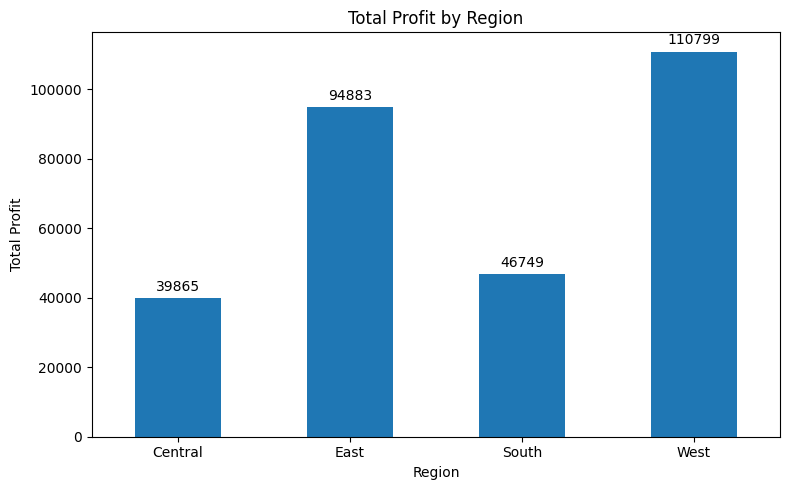

In [20]:
import matplotlib.pyplot as plt

region_profit = sales_report.groupby("Region")["Profit"].sum()

ax = region_profit.plot(kind="bar", figsize=(8, 5))

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

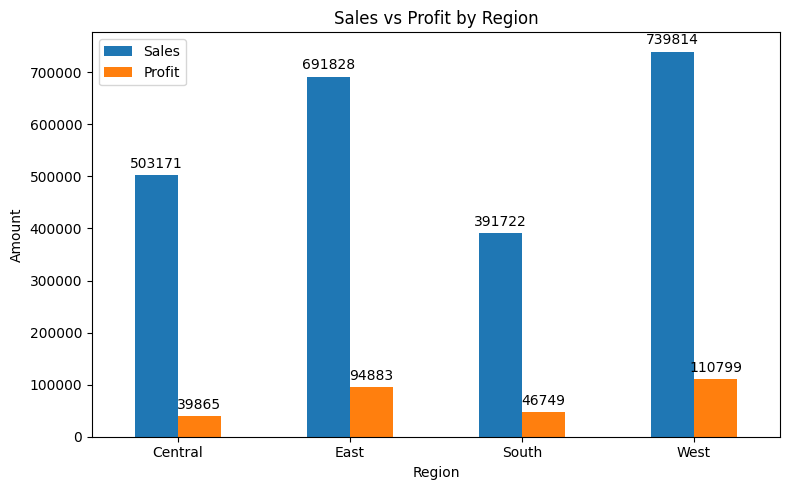

In [21]:
import matplotlib.pyplot as plt
# Calculate total sales and profit for each region
region_data = sales_report.groupby("Region")[["Sales", "Profit"]].sum()
# Create a bar chart
ax = region_data.plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Sales vs Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=360)
# Label the first group of bars
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
# Label the second group of bars
ax.bar_label(ax.containers[1], fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

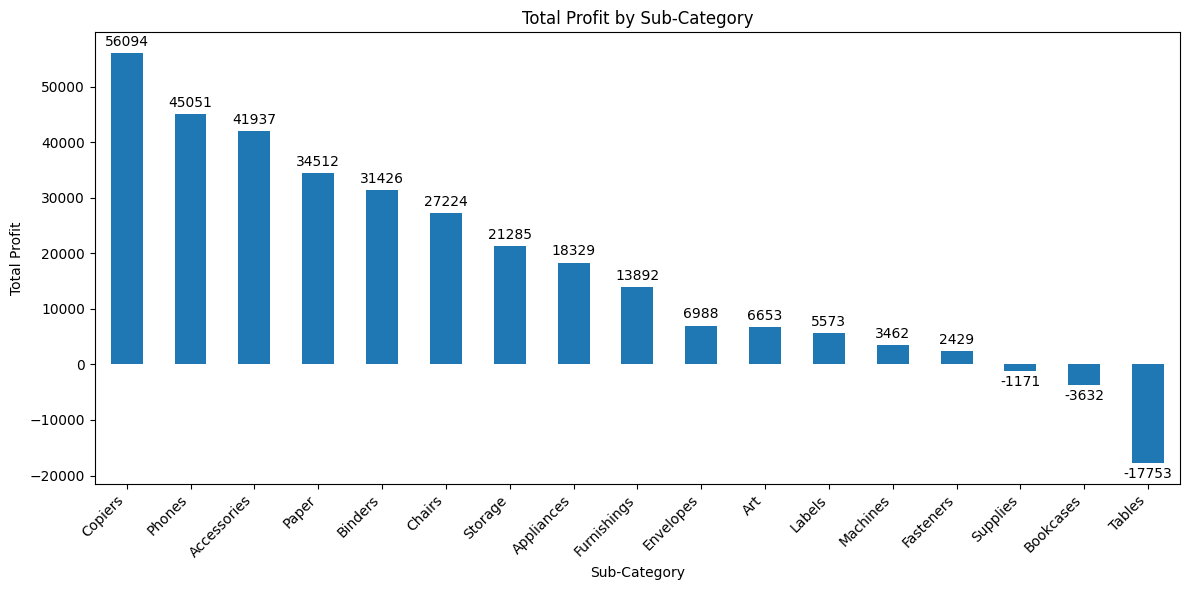

In [22]:
# Calculate total profit for each sub-category
subcategory_profit = (
    sales_report.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)
# Create the bar chart
ax = subcategory_profit.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45, ha="right")
# Display profit values above the bars
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

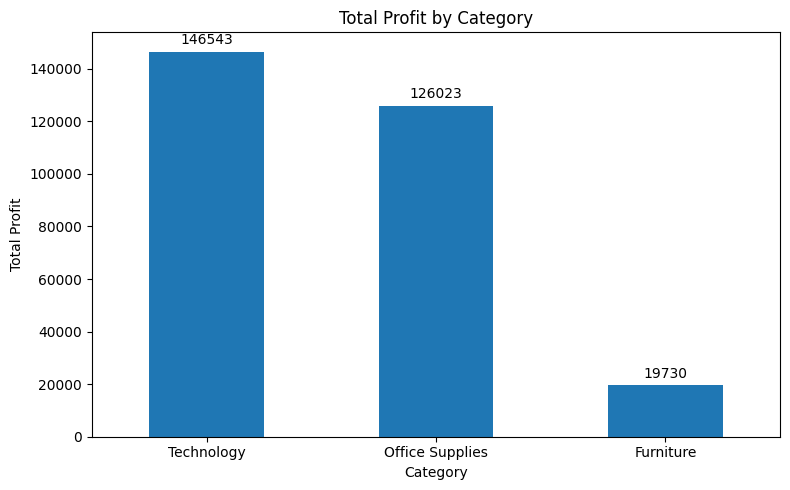

In [23]:
# Calculate total profit by category
category_profit = (
    sales_report.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

# Create the bar chart
ax = category_profit.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)

# Add profit labels
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

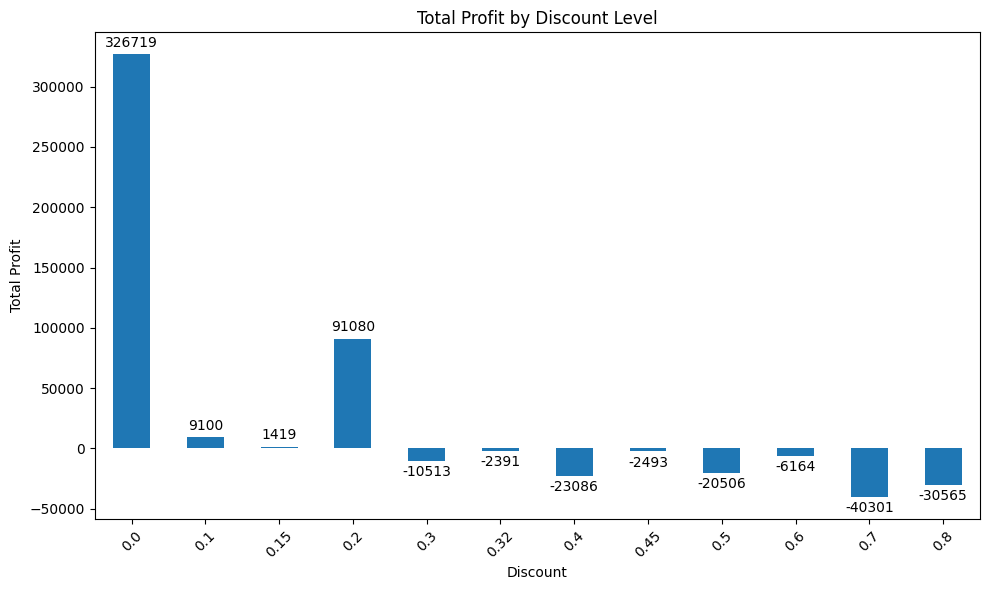

In [24]:
# Calculate total profit for each discount level
discount_profit = (
    sales_report.groupby("Discount")["Profit"]
    .sum()
    .sort_index()
)
# Create the bar chart
ax = discount_profit.plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
# Display profit labels
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

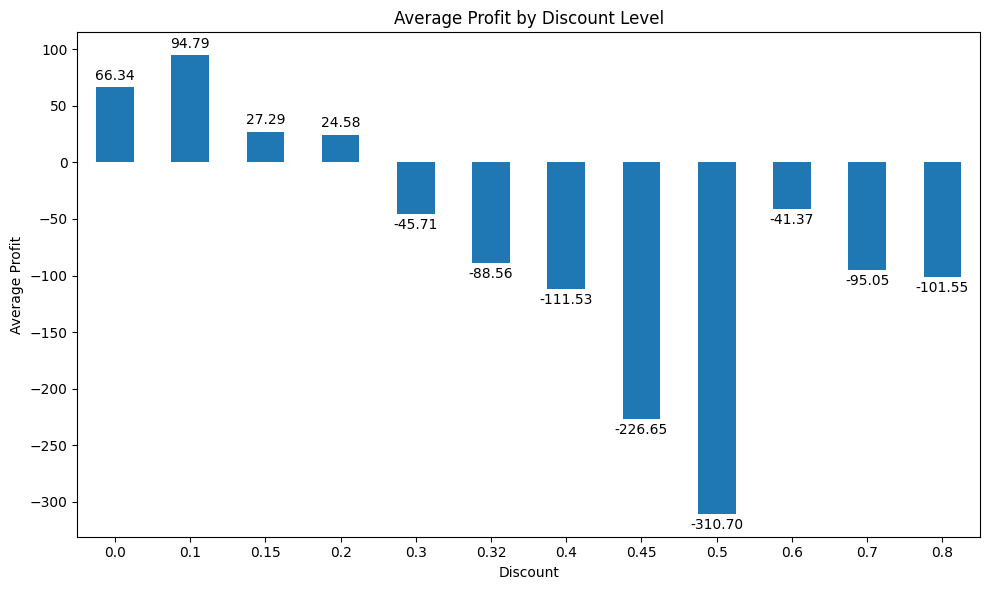

In [25]:
# Calculate average profit for each discount
discount_avg_profit = (
    sales_report.groupby("Discount")["Profit"]
    .mean()
    .sort_index()
    .round(2)
)

# Create the bar chart
ax = discount_avg_profit.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.xticks(rotation=0)

# Display average profit labels
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

In [26]:
discount_category_analysis = (
    sales_report.groupby(["Discount", "Category"])["Profit"]
    .agg(["count", "mean", "sum"])
    .round(2)
)
print(discount_category_analysis)

                          count    mean        sum
Discount Category                                 
0.00     Furniture          880   67.59   59476.99
         Office Supplies   3198   41.87  133891.90
         Technology         847  157.44  133349.70
0.10     Furniture           78   92.07    7181.80
         Office Supplies     16   67.88    1086.08
         Technology           2  416.04     832.08
0.15     Furniture           52   27.29    1418.99
0.20     Furniture          636   10.39    6608.50
         Office Supplies   2225   17.24   38351.70
         Technology         845   54.58   46119.75
0.30     Furniture          224  -48.16  -10786.83
         Office Supplies      1  -52.66     -52.66
         Technology           5   65.21     326.04
0.32     Furniture           27  -88.56   -2391.14
0.40     Furniture           75 -215.83  -16187.40
         Office Supplies      1  -29.32     -29.32
         Technology         131  -52.44   -6869.65
0.45     Furniture           11

In [27]:
print(discount_category_analysis.loc[0.10])

                 count    mean      sum
Category                               
Furniture           78   92.07  7181.80
Office Supplies     16   67.88  1086.08
Technology           2  416.04   832.08


In [28]:
category_discount_mean = (
    sales_report
    .groupby(["Category", "Discount"])["Profit"]
    .mean()
    .round(2)
)

print(category_discount_mean)

Category         Discount
Furniture        0.00         67.59
                 0.10         92.07
                 0.15         27.29
                 0.20         10.39
                 0.30        -48.16
                 0.32        -88.56
                 0.40       -215.83
                 0.45       -226.65
                 0.50       -238.36
                 0.60        -41.73
                 0.70       -240.74
Office Supplies  0.00         41.87
                 0.10         67.88
                 0.20         17.24
                 0.30        -52.66
                 0.40        -29.32
                 0.60        -15.14
                 0.70        -43.30
                 0.80       -101.55
Technology       0.00        157.44
                 0.10        416.04
                 0.20         54.58
                 0.30         65.21
                 0.40        -52.44
                 0.50       -636.27
                 0.70       -851.27
Name: Profit, dtype: float64


In [29]:
furniture_discount = (
    sales_report[sales_report["Category"] == "Furniture"]
    .groupby("Discount")["Profit"]
    .agg(["count", "mean", "sum"])
    .round(2)
)

print(furniture_discount)

          count    mean       sum
Discount                         
0.00        880   67.59  59476.99
0.10         78   92.07   7181.80
0.15         52   27.29   1418.99
0.20        636   10.39   6608.50
0.30        224  -48.16 -10786.83
0.32         27  -88.56  -2391.14
0.40         75 -215.83 -16187.40
0.45         11 -226.65  -2493.11
0.50         54 -238.36 -12871.20
0.60        147  -41.73  -6134.07
0.70         17 -240.74  -4092.54


In [30]:
high_discount_furniture = sales_report[
    (sales_report["Category"] == "Furniture") &
    (sales_report["Discount"] > 0.20)
]

print(
    high_discount_furniture[
        ["Sub-Category", "Sales", "Quantity", "Discount", "Profit"]
    ].head(10)
)

    Sub-Category     Sales  Quantity  Discount    Profit
14   Furnishings    76.728         3       0.6  -53.7096
32     Bookcases    61.960         4       0.5  -53.2856
39     Bookcases   181.470         5       0.7 -320.5970
118  Furnishings    25.160         5       0.6  -11.3220
130       Chairs   634.116         6       0.3 -172.1172
131       Chairs   362.250         6       0.3    0.0000
133  Furnishings    63.552         6       0.6  -34.9536
134       Tables   376.509         3       0.3  -43.0296
144    Bookcases   302.450         5       0.5 -199.6170
198       Tables  1071.576         4       0.4 -553.6476


In [31]:
high_discount_furniture["Profit"].agg(
    ["count", "mean", "sum", "min", "max"]
).round(2)

count      555.00
mean       -99.02
sum     -54956.29
min      -1862.31
max         41.93
Name: Profit, dtype: float64

In [1]:
sales_report.to_csv("sales_report.csv", index=False)

NameError: name 'sales_report' is not defined